In [27]:


import os
import json
import pandas as pd
from datetime import datetime, timezone

import duckdb
DB_PATH = r"C:\Users\kjchr\Desktop\hockey\new_hockey_env\API data\duckdb\nhl_data.duckdb"
con = duckdb.connect(DB_PATH) 
print("Connected:", DB_PATH)

try:
    import shap
    SHAP_AVAILABLE = True
except ImportError:
    SHAP_AVAILABLE = False
    print("⚠️ SHAP not installed — using permutation importance fallback.")


# Suppress SettingWithCopyWarning
pd.options.mode.chained_assignment = None
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)


Connected: C:\Users\kjchr\Desktop\hockey\new_hockey_env\API data\duckdb\nhl_data.duckdb


In [28]:

# con.close()
# print("DuckDB connection closed.")

### Training

In [29]:
train_df = con.execute('select* from history_data').df()
train_df = train_df[train_df["season_id"] != 20192020]
train_df = train_df[train_df["season_id"] != 20202021]

assert (
    train_df
    .groupby(["season_id", "tri_code"])["made_playoffs"]
    .nunique()
    .le(1)
    .all()
), "made_playoffs varies within a team-season"
train_df = train_df.sort_values(by=['season_id','tri_code', 'game_id'])

conference_sizes = (
    train_df.groupby(["season_id", "conference"])["tri_code"]
    .nunique()
    .reset_index()
    .rename(columns={"tri_code": "conference_team_count"})
)

train_df = train_df.merge(conference_sizes, on=["season_id", "conference"], how="left")

train_df["conf_playoff_chance_baseline"] = 8 / train_df["conference_team_count"]

train_df["streak_direction"] = train_df["streak"].map({
    "W": 1,
    "L": -1
}).fillna(0).astype(int)


train_df["streak_signed"] = (
    train_df["streak_direction"] *
    train_df["streak_count"].fillna(0).astype(int)
)


train_df["streak_signed"] = train_df["streak_signed"].clip(-7, 7)


train_df.drop(columns=["streak", "streak_direction"], inplace=True)


assert (
    train_df
    .groupby(["season_id", "tri_code", "game_date"])["streak_signed"]
    .nunique()
    .le(1)
    .all()
), "❌ streak_signed varies within a team-day"

print("✅ streak_signed feature created successfully")
def bucket_rank(rank):
    if rank <= 3:
        return "tier1_elite"
    elif rank <= 6:
        return "tier2_strong"
    elif rank <= 10:
        return "tier3_bubble"
    else:
        return "tier4_bottom"
        
train_df["rank_bucket"] = train_df["conference_rank"].apply(bucket_rank)

# =====================================================
# DROP HIGH-NOISE / HIGH-RISK FEATURES (MODEL ONLY)
# =====================================================

DROP_COLS = [

    # -------------------------------------------------
    # 1. SINGLE-GAME RAW STATS (NOISY)
    # -------------------------------------------------
    "shots_for",
    "shots_against",
    "goals_for",
    "goals_against",

    "hd_sog",
    "md_sog",
    "ld_sog",

    "hd_goals",
    "md_goals",
    "ld_goals",

    "hd_against",
    "md_against",
    "ld_against",

    "game_savePct",
    "game_GAA",

    # -------------------------------------------------
    # 2. RAW PER-GAME SPECIAL TEAMS COUNTS
    # (keep cumulative / per-game rates instead)
    # -------------------------------------------------
    "pp_gf",
    "pp_ga",
    "sh_gf",
    "sh_ga",
    "times_sh",

    # -------------------------------------------------
    # 3. REDUNDANT / DOMINANT RANK FEATURES
    # (keep rank_bucket + conference_rank only)
    # -------------------------------------------------

    "division_home_rank",
    "division_road_rank",
    "division_last_10_rank",

    "conference_home_rank",
    "conference_road_rank",
    "conference_last_10_rank",

    "league_rank",
    "league_home_rank",
    "league_road_rank",
    "league_last_10_rank",



    # -------------------------------------------------
    # 4. OPTIONAL: STRONG LATE-SEASON PROXIES
    # (uncomment if probabilities converge too fast)
    # -------------------------------------------------
    # "in_playoff_spot",
]

# =====================================================
# APPLY DROP (SAFE — ignores missing)
# =====================================================

print(f"Dropping {len(DROP_COLS)} high-risk features...")

train_df_model = train_df.drop(columns=DROP_COLS, errors="ignore")

print("Remaining feature count:", train_df_model.shape[1])

train_df_model.head()



✅ streak_signed feature created successfully
Dropping 30 high-risk features...
Remaining feature count: 173


,season_id,game_id,game_date,team_id,tri_code,team_name,win,wins_before,games_before,win_pct_before,sos_past,sos_future,pp_opp,pp_opp_pg,pp_toi,pp_gpg,pp_net_g,pp_net_gpg,pp_pct,pp_net_pct,sh_ga_pg,times_sh_pg,pk_net_pct,pk_pct,pk_net_g,pk_net_gpg,pk_toi_pg,pp_ga_pg,sh_gf_pg,c_pp_opps,c_pp_net_g,net_pp_pct,ppng_rank,c_pp_ga,c_times_sh,net_pk_pct,pk_rank,rush_shots_for,rush_shots_against,rush_shot_differential,c_rush_shots_for,c_rush_shots_against,c_rush_diff,rush_for_per_game,rush_against_per_game,rush_diff_per_game,shot_attempts_for,shot_attempts_against,shot_attempts_differential,corsi_for,corsi_against,corsi_diff,c_shots_diff,games_played,shot_attempts_for_per_game,shot_attempts_against_per_game,shots_diff_per_game,SCF,SCSF,SCGF,SCA,HDCF,MDCF,LDCF,HDCA,MDCA,LDCA,HDCF_pct,HDCA_pct,MDCF_pct,MDCA_pct,LDCF_pct,LDCA_pct,c_SCF,c_SCSF,c_SCGF,c_SCA,SCF_pg,SCA_pg,c_HDCF,c_HDCA,c_MDCF,c_MDCA,c_LDCF,c_LDCA,shot_pct,sv_pct,pdo,c_goals_for,c_hd_sog,c_md_sog,c_ld_sog,c_hd_goals,c_md_goals,c_ld_goals,c_goals_against,c_hd_against,c_md_against,c_ld_against,c_shot_pct,c_sv_pct,c_pdo,c_shots_for,c_shots_against,c_corsi_for,c_corsi_against,c_corsi_diff,corsi_diff_per_game,games_remaining,wins,wins_pctg,losses,ot_losses,rotw,rotw_pctg,rw,so_losses,so_wins,points,points_pct,projected_points,in_playoff_spot,gf_pctg,goal_diff,goal_diff_pctg,streak_count,last_10_gp,last_10_wins,last_10_losses,last_10_otl,last_10_points,last_10_gf,last_10_ga,last_10_goal_diff,last_10_rotw,last_10_rw,home_gp,home_wins,home_losses,home_otlosses,home_rotw,home_rw,home_points,home_gf,home_ga,home_goal_diff,road_gp,road_wins,road_losses,road_ot_losses,road_rotw,road_rw,road_points,road_gf,road_ga,road_goal_diff,division,division_rank,conference,conference_rank,wildcard_rank,made_playoffs,ot_wins,overtimes,ot_games_pct,pt_pct_x_sos,gaa_x_sv,gd_x_rushdiff,pk_load_x_pk_pct,conference_team_count,conf_playoff_chance_baseline,streak_signed,rank_bucket
0,20132014,2013020006,2013-10-02,24,ANA,Anaheim Ducks,0,<NA>,0,NaN,NaN,0.494599,2,2.0,240.0,0.0,0,0.0,0.00000,0.000000,0.0,4.0,0.500000,0.50000,-2,-2.0,369.0,2.0,0.0,2.0,0.0,0.0,6,2.0,4.0,50.0,6,2,2,0,2,2,0,2.0,2.000000,0.000000,59,58,1,44.0,42.0,2.0,1,1,59.000000,58.000000,1.000000,23,36,1,51.0,10,19,31,8,16,32,0.555556,0.444444,0.542857,0.457143,0.492063,0.507937,23,36,1,51.0,23.000000,51.000000,10,8,19,16,31,32,2.777778,79.310345,82.088123,1,8,8,21,1,0,0,6,4,9,16,0.027778,0.793103,82.088123,59,58,44.0,42.0,2.0,2.0,81,0,0.000000,1,0,0,0.000000,0,0,0,0,0.000000,0,0,1.000000,-5,-5.00,1.0,1,0,1,0,0,1,6,-5,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,1,6,-5,Pacific,7,Western,14,8,1,0,0,0.00,0.000000,4.758600,0,2.00000,14,0.571429,-1,tier4_bottom
1,20132014,2013020029,2013-10-05,24,ANA,Anaheim Ducks,1,0,1,0.000000,0.000000,0.494599,3,3.0,348.0,1.0,1,1.0,0.33333,0.333333,0.0,4.0,0.500000,0.50000,-2,-2.0,303.0,2.0,0.0,5.0,1.0,20.0,9,4.0,8.0,50.0,15,4,4,0,6,6,0,3.0,3.000000,0.000000,43,42,1,31.0,30.0,1.0,2,2,51.000000,50.000000,1.000000,28,30,4,55.0,7,15,22,9,19,27,0.437500,0.562500,0.441176,0.558824,0.448980,0.551020,51,66,5,106.0,25.500000,53.000000,17,17,34,35,53,59,13.333333,90.909091,104.242424,5,13,18,36,4,1,0,9,14,17,31,0.075758,0.854839,93.059629,102,100,75.0,72.0,3.0,1.5,80,1,0.500000,1,0,1,0.500000,0,0,0,2,0.500000,82,0,2.500000,-4,-2.00,1.0,2,1,1,0,2,5,9,-4,1,0,0,0,0,0,0,0,0,0,0,0,2,1,1,0,1,0,2,5,9,-4,Pacific,5,Western,10,4,1,1,1,0.50,0.247299,2.520707,0,2.00000,14,0.571429,1,tier3_bubble
2,20132014,2013020033,2013-10-06,24,ANA,Anaheim Ducks,1,1,2,0.500000,0.500000,0.500781,4,4.0,480.0,0.0,0,0.0,0.00000,0.000000,0.0,3.0,0.666666,0.66666,-1,-1.0,251.0,1.0,0.0,9.0,1.0,11.1,13,5.0,11.0,45.5,15,6,5,1,12,11,1,4.0,3.666667,0.333333,61,61,0,48.0,45.0,3.0,2,3,54.333333,53.666667,0.666667,40,34,3,63.0,14,22,27,15,28,25,0.482759,0.517241,0.440000,0.560000,0.519231,0.480769,91,100,8,169.0,30.333333,56.333333,31,32,56,63,80,84,8.823529,88.235294,97.058824,8,23,32,48,7,1,0,11,17,22,40,0.080000,0.860759,94.075949,163,161,123.0,117.0,6.0,2.0,79,2

### Testing

In [30]:
test_df = con.execute('select* from current_data').df()
test_df = test_df.sort_values(by=['season_id','tri_code', 'game_id'])

conference_sizes = (
    test_df.groupby(["season_id", "conference"])["tri_code"]
    .nunique()
    .reset_index()
    .rename(columns={"tri_code": "conference_team_count"})
)

test_df = test_df.merge(conference_sizes, on=["season_id", "conference"], how="left")

test_df["conf_playoff_chance_baseline"] = 8 / test_df["conference_team_count"]
test_df["streak_direction"] = test_df["streak"].map({
    "W": 1,
    "L": -1
}).fillna(0).astype(int)


test_df["streak_signed"] = (
    test_df["streak_direction"] *
    test_df["streak_count"].fillna(0).astype(int)
)


test_df["streak_signed"] = test_df["streak_signed"].clip(-7, 7)


test_df.drop(columns=["streak", "streak_direction"], inplace=True)


assert (
    test_df
    .groupby(["season_id", "tri_code", "game_date"])["streak_signed"]
    .nunique()
    .le(1)
    .all()
), "❌ streak_signed varies within a team-day"

print("✅ streak_signed feature created successfully")
def bucket_rank(rank):
    if rank <= 3:
        return "tier1_elite"
    elif rank <= 6:
        return "tier2_strong"
    elif rank <= 10:
        return "tier3_bubble"
    else:
        return "tier4_bottom"
        
test_df["rank_bucket"] = test_df["conference_rank"].apply(bucket_rank)
# =====================================================
# DROP HIGH-NOISE / HIGH-RISK FEATURES (MODEL ONLY)
# =====================================================

DROP_COLS = [

    # -------------------------------------------------
    # 1. SINGLE-GAME RAW STATS (NOISY)
    # -------------------------------------------------
    "shots_for",
    "shots_against",
    "goals_for",
    "goals_against",

    "hd_sog",
    "md_sog",
    "ld_sog",

    "hd_goals",
    "md_goals",
    "ld_goals",

    "hd_against",
    "md_against",
    "ld_against",

    "game_savePct",
    "game_GAA",

    # -------------------------------------------------
    # 2. RAW PER-GAME SPECIAL TEAMS COUNTS
    # (keep cumulative / per-game rates instead)
    # -------------------------------------------------
    "pp_gf",
    "pp_ga",
    "sh_gf",
    "sh_ga",
    "times_sh",

    # -------------------------------------------------
    # 3. REDUNDANT / DOMINANT RANK FEATURES
    # (keep rank_bucket + conference_rank only)
    # -------------------------------------------------

    "division_home_rank",
    "division_road_rank",
    "division_last_10_rank",

    "conference_home_rank",
    "conference_road_rank",
    "conference_last_10_rank",

    "league_rank",
    "league_home_rank",
    "league_road_rank",
    "league_last_10_rank",



    # -------------------------------------------------
    # 4. OPTIONAL: STRONG LATE-SEASON PROXIES
    # (uncomment if probabilities converge too fast)
    # -------------------------------------------------
    # "in_playoff_spot",
]

# =====================================================
# APPLY DROP (SAFE — ignores missing)
# =====================================================

print(f"Dropping {len(DROP_COLS)} high-risk features...")

current_df = test_df.drop(columns=DROP_COLS, errors="ignore")

print("Remaining feature count:", current_df.shape[1])

current_df.head()


✅ streak_signed feature created successfully
Dropping 30 high-risk features...
Remaining feature count: 172


,season_id,game_id,game_date,team_id,tri_code,team_name,win,wins_before,games_before,win_pct_before,sos_past,sos_future,pp_opp,pp_opp_pg,pp_toi,pp_gpg,pp_net_g,pp_net_gpg,pp_pct,pp_net_pct,sh_ga_pg,times_sh_pg,pk_net_pct,pk_pct,pk_net_g,pk_net_gpg,pk_toi_pg,pp_ga_pg,sh_gf_pg,c_pp_opps,c_pp_net_g,net_pp_pct,ppng_rank,c_pp_ga,c_times_sh,net_pk_pct,pk_rank,rush_shots_for,rush_shots_against,rush_shot_differential,c_rush_shots_for,c_rush_shots_against,c_rush_diff,rush_for_per_game,rush_against_per_game,rush_diff_per_game,shot_attempts_for,shot_attempts_against,shot_attempts_differential,corsi_for,corsi_against,corsi_diff,c_shots_diff,games_played,shot_attempts_for_per_game,shot_attempts_against_per_game,shots_diff_per_game,SCF,SCSF,SCGF,SCA,HDCF,MDCF,LDCF,HDCA,MDCA,LDCA,HDCF_pct,HDCA_pct,MDCF_pct,MDCA_pct,LDCF_pct,LDCA_pct,c_SCF,c_SCSF,c_SCGF,c_SCA,SCF_pg,SCA_pg,c_HDCF,c_HDCA,c_MDCF,c_MDCA,c_LDCF,c_LDCA,shot_pct,sv_pct,pdo,c_goals_for,c_hd_sog,c_md_sog,c_ld_sog,c_hd_goals,c_md_goals,c_ld_goals,c_goals_against,c_hd_against,c_md_against,c_ld_against,c_shot_pct,c_sv_pct,c_pdo,c_shots_for,c_shots_against,c_corsi_for,c_corsi_against,c_corsi_diff,corsi_diff_per_game,games_remaining,wins,wins_pctg,losses,ot_losses,rotw,rotw_pctg,rw,so_losses,so_wins,points,points_pct,projected_points,in_playoff_spot,gf_pctg,goal_diff,goal_diff_pctg,streak_count,last_10_gp,last_10_wins,last_10_losses,last_10_otl,last_10_points,last_10_gf,last_10_ga,last_10_goal_diff,last_10_rotw,last_10_rw,home_gp,home_wins,home_losses,home_otlosses,home_rotw,home_rw,home_points,home_gf,home_ga,home_goal_diff,road_gp,road_wins,road_losses,road_ot_losses,road_rotw,road_rw,road_points,road_gf,road_ga,road_goal_diff,division,division_rank,conference,conference_rank,wildcard_rank,ot_wins,overtimes,ot_games_pct,pt_pct_x_sos,gaa_x_sv,gd_x_rushdiff,pk_load_x_pk_pct,conference_team_count,conf_playoff_chance_baseline,streak_signed,rank_bucket
0,20252026,2025020021,2025-10-09,24,ANA,Anaheim Ducks,0,<NA>,0,NaN,NaN,0.495047,1,1.0,120.0,0.0,0,0.0,0.00000,0.000000,0.0,2.0,1.000000,1.00000,0,0.0,240.0,0.0,0.0,1.0,0.0,0.0,9,0.0,2.0,0.0,1,17,11,6,17,11,6,17.0,11.000000,6.000000,87,86,1,57,60,-3,1,1,87.000000,86.000000,1.00,24,36,1,60,19,17,52,9,15,41,0.678571,0.321429,0.531250,0.468750,0.559140,0.440860,24,36,1,60,24.000000,60.000000,19,9,17,15,52,41,2.777778,90.322581,93.100358,1,6,9,21,1,0,0,3,5,9,17,0.027778,0.903226,93.100358,87,86,57,60,-3,-3.000000,81,0,0.000000,1,0,0,0.000000,0,0,0,0,0.000000,0,0,1.00,-2,-2.00,1.0,1,0,1,0,0,1,3,-2,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,1,3,-2,Pacific,8,Western,15,9,0,0,0.00,0.000000,2.851438,-12,2.00000,16,0.5,-1,tier4_bottom
1,20252026,2025020036,2025-10-11,24,ANA,Anaheim Ducks,1,0,1,0.000000,0.000000,0.495047,4,4.0,428.0,2.0,2,2.0,0.50000,0.500000,0.0,4.0,0.500000,0.50000,-2,-2.0,343.0,2.0,0.0,5.0,2.0,40.0,3,2.0,6.0,33.3,12,8,9,-1,25,20,5,12.5,10.000000,2.500000,85,84,1,64,58,6,2,2,86.000000,85.000000,1.00,43,44,7,75,32,19,38,28,19,36,0.533333,0.466667,0.500000,0.500000,0.513514,0.486486,67,80,8,135,33.500000,67.500000,51,37,36,34,90,77,15.909091,73.913043,89.822134,8,22,20,41,6,3,0,9,9,19,26,0.100000,0.833333,93.333333,172,170,121,118,3,1.500000,80,1,0.500000,1,0,1,0.500000,0,0,0,2,0.500000,82,0,4.00,-1,-0.50,1.0,2,1,1,0,2,8,9,-1,1,0,0,0,0,0,0,0,0,0,0,0,2,1,1,0,1,0,2,8,9,-1,Pacific,5,Western,12,6,1,1,0.50,0.247524,4.448365,1,2.00000,16,0.5,1,tier4_bottom
2,20252026,2025020056,2025-10-14,24,ANA,Anaheim Ducks,1,1,2,0.500000,0.333333,0.512727,6,6.0,429.0,2.0,2,2.0,0.33333,0.333333,0.0,1.0,1.000000,1.00000,0,0.0,120.0,0.0,0.0,11.0,4.0,36.4,2,2.0,7.0,28.6,14,11,9,2,36,29,7,12.0,9.666667,2.333333,69,68,1,43,44,-1,3,3,80.333333,79.333333,1.00,37,22,4,73,13,29,29,15,26,23,0.464286,0.535714,0.527273,0.472727,0.557692,0.442308,104,102,12,208,34.666667,69.333333,64,52,65,60,119,100,18.181818,88.000000,106.181818,12,25,29,51,7,4,2,12,20,26,34,0.117647,0.848101,96.574832,241,238,164,162,2,0.666667,79,2,0.666667,1,0,2,0.666667,1,0,0,4,0.666667,109,0,4.00,0,0.00

### Loading

In [31]:
# =====================================================
# LOAD MODEL ARTIFACTS
# =====================================================

from prediction_model import load_and_score
from joblib import load

bundle = load("models/playoff_xgb_pipeline_wc_field_pressure_v1.joblib")

pipeline = bundle["pipeline"]
FEATURE_COLS = bundle["features"]

xgb_model = pipeline.named_steps["model"]
scaler = pipeline.named_steps["scaler"]

# =====================================================
# 1. SCORE CURRENT DATA (adds WC features)
# =====================================================

current_df = load_and_score(current_df)
# =====================================================
# PRESENTATION LAYER (NON-MODEL)
# =====================================================

def season_bucket(gp):
    if gp <= 20:
        return "early"
    elif gp <= 50:
        return "mid"
    else:
        return "late"

def adjust_for_uncertainty(p, bucket):
    """
    Compress early-season probabilities toward 50%.
    Presentation-only — does NOT affect model.
    """
    if bucket == "early":
        return 0.45 * p + 0.275
    return p

# Ensure season context exists
if "season_bucket" not in current_df.columns:
    current_df["season_bucket"] = (
        current_df["games_played"].apply(season_bucket)
    )

# Display-safe probability
current_df["playoff_prob_display"] = current_df.apply(
    lambda r: adjust_for_uncertainty(
        r["playoff_prob_row"],
        r["season_bucket"]
    ),
    axis=1
)


# =====================================================
# 2. BUILD SHAP FEATURE MATRIX (AFTER scoring)
# =====================================================

LEAK_COLS = [
    "game_id", "game_date", "date",
    "clinch_type", "made_playoffs",
    "team_name", "opponent",
    "season_id"
]

ID_COLS = ["team_id", "opponent_id", "tri_code"]

X_shap = (
    current_df
    .drop(columns=LEAK_COLS + ID_COLS, errors="ignore")
    .select_dtypes(include="number")
    .fillna(0)
    .reindex(columns=FEATURE_COLS, fill_value=0)
)

# =====================================================
# 3. APPLY SCALER (what the model actually sees)
# =====================================================

X_shap_scaled = scaler.transform(X_shap)

X_shap_scaled = pd.DataFrame(
    X_shap_scaled,
    columns=X_shap.columns,
    index=X_shap.index
)

current_df.head()


,season_id,game_id,game_date,team_id,tri_code,team_name,win,wins_before,games_before,win_pct_before,sos_past,sos_future,pp_opp,pp_opp_pg,pp_toi,pp_gpg,pp_net_g,pp_net_gpg,pp_pct,pp_net_pct,sh_ga_pg,times_sh_pg,pk_net_pct,pk_pct,pk_net_g,pk_net_gpg,pk_toi_pg,pp_ga_pg,sh_gf_pg,c_pp_opps,c_pp_net_g,net_pp_pct,ppng_rank,c_pp_ga,c_times_sh,net_pk_pct,pk_rank,rush_shots_for,rush_shots_against,rush_shot_differential,c_rush_shots_for,c_rush_shots_against,c_rush_diff,rush_for_per_game,rush_against_per_game,rush_diff_per_game,shot_attempts_for,shot_attempts_against,shot_attempts_differential,corsi_for,corsi_against,corsi_diff,c_shots_diff,games_played,shot_attempts_for_per_game,shot_attempts_against_per_game,shots_diff_per_game,SCF,SCSF,SCGF,SCA,HDCF,MDCF,LDCF,HDCA,MDCA,LDCA,HDCF_pct,HDCA_pct,MDCF_pct,MDCA_pct,LDCF_pct,LDCA_pct,c_SCF,c_SCSF,c_SCGF,c_SCA,SCF_pg,SCA_pg,c_HDCF,c_HDCA,c_MDCF,c_MDCA,c_LDCF,c_LDCA,shot_pct,sv_pct,pdo,c_goals_for,c_hd_sog,c_md_sog,c_ld_sog,c_hd_goals,c_md_goals,c_ld_goals,c_goals_against,c_hd_against,c_md_against,c_ld_against,c_shot_pct,c_sv_pct,c_pdo,c_shots_for,c_shots_against,c_corsi_for,c_corsi_against,c_corsi_diff,corsi_diff_per_game,games_remaining,wins,wins_pctg,losses,ot_losses,rotw,rotw_pctg,rw,so_losses,so_wins,points,points_pct,projected_points,in_playoff_spot,gf_pctg,goal_diff,goal_diff_pctg,streak_count,last_10_gp,last_10_wins,last_10_losses,last_10_otl,last_10_points,last_10_gf,last_10_ga,last_10_goal_diff,last_10_rotw,last_10_rw,home_gp,home_wins,home_losses,home_otlosses,home_rotw,home_rw,home_points,home_gf,home_ga,home_goal_diff,road_gp,road_wins,road_losses,road_ot_losses,road_rotw,road_rw,road_points,road_gf,road_ga,road_goal_diff,division,division_rank,conference,conference_rank,wildcard_rank,ot_wins,overtimes,ot_games_pct,pt_pct_x_sos,gaa_x_sv,gd_x_rushdiff,pk_load_x_pk_pct,conference_team_count,conf_playoff_chance_baseline,streak_signed,rank_bucket,wc2_points,wc2_points_pct,wc_points_margin,wc_points_pct_margin,in_wc_spot,in_div_top3,on_wc_bubble,wc_teams_within_2pts,wc_teams_within_4pts,wc_teams_within_6pts,playoff_prob_row,season_bucket,playoff_prob_display
0,20252026,2025020021,2025-10-09,24,ANA,Anaheim Ducks,0,<NA>,0,NaN,NaN,0.495047,1,1.0,120.0,0.0,0,0.0,0.00000,0.000000,0.0,2.0,1.000000,1.00000,0,0.0,240.0,0.0,0.0,1.0,0.0,0.0,9,0.0,2.0,0.0,1,17,11,6,17,11,6,17.0,11.000000,6.000000,87,86,1,57,60,-3,1,1,87.000000,86.000000,1.00,24,36,1,60,19,17,52,9,15,41,0.678571,0.321429,0.531250,0.468750,0.559140,0.440860,24,36,1,60,24.000000,60.000000,19,9,17,15,52,41,2.777778,90.322581,93.100358,1,6,9,21,1,0,0,3,5,9,17,0.027778,0.903226,93.100358,87,86,57,60,-3,-3.000000,81,0,0.000000,1,0,0,0.000000,0,0,0,0,0.000000,0,0,1.00,-2,-2.00,1.0,1,0,1,0,0,1,3,-2,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,1,3,-2,Pacific,8,Western,15,9,0,0,0.00,0.000000,2.851438,-12,2.00000,16,0.5,-1,tier4_bottom,2.0,0.5,-2.0,-0.500000,0,0,0,8,8,8,0.342030,early,0.428913
1,20252026,2025020036,2025-10-11,24,ANA,Anaheim Ducks,1,0,1,0.000000,0.000000,0.495047,4,4.0,428.0,2.0,2,2.0,0.50000,0.500000,0.0,4.0,0.500000,0.50000,-2,-2.0,343.0,2.0,0.0,5.0,2.0,40.0,3,2.0,6.0,33.3,12,8,9,-1,25,20,5,12.5,10.000000,2.500000,85,84,1,64,58,6,2,2,86.000000,85.000000,1.00,43,44,7,75,32,19,38,28,19,36,0.533333,0.466667,0.500000,0.500000,0.513514,0.486486,67,80,8,135,33.500000,67.500000,51,37,36,34,90,77,15.909091,73.913043,89.822134,8,22,20,41,6,3,0,9,9,19,26,0.100000,0.833333,93.333333,172,170,121,118,3,1.500000,80,1,0.500000,1,0,1,0.500000,0,0,0,2,0.500000,82,0,4.00,-1,-0.50,1.0,2,1,1,0,2,8,9,-1,1,0,0,0,0,0,0,0,0,0,0,0,2,1,1,0,1,0,2,8,9,-1,Pacific,5,Western,12,6,1,1,0.50,0.247524,4.448365,1,2.00000,16,0.5,1,tier4_bottom,2.0,0.5,0.0,0.000000,0,0,0,9,9,9,0.727317,early,0.602293
2,20252026,2025020056,2025-10-14,24,ANA,Anaheim Ducks,1,1,2,0.500000,0.333333,0.512727,6,6.0,429.0,2.0,2,2.0,0.33333,0.333333,0.0,1.0,1.000000,1.00000,0,0.0,120.0,0.0,0.0,11.0,4.0,36.4,2,2.0,7.0,28.6,14,11,9,2,36,29,7,12.0,9.666667,2.333333,69,68,1,43,44,-1,3,3,80.333333,7

In [32]:
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_shap_scaled)

def explain_team(
    team_code: str,
    current_df: pd.DataFrame,
    X_shap_scaled: pd.DataFrame,
    shap_values,
    explainer,
    feature_cols,
    n=8
):
    """
    Explain why a team is at its current playoff odds.
    Returns helpful + harmful driver tables.
    """

    # -------------------------------------------------
    # Locate latest row for team
    # -------------------------------------------------
    team_mask = current_df["tri_code"] == team_code
    if not team_mask.any():
        raise ValueError(f"Team {team_code} not found")

    row_idx = current_df.loc[team_mask].index[-1]

    # -------------------------------------------------
    # Extract SHAP row
    # -------------------------------------------------
    shap_row = pd.Series(
        shap_values[row_idx],
        index=feature_cols
    ).sort_values()

    most_harmful = shap_row.head(n)
    most_helpful = shap_row.tail(n)

    # -------------------------------------------------
    # Season stage (defensive)
    # -------------------------------------------------
    if "season_bucket" in current_df.columns:
        season_stage = current_df.loc[row_idx, "season_bucket"]
    elif "games_played" in current_df.columns:
        gp = current_df.loc[row_idx, "games_played"]
        season_stage = (
            "early" if gp <= 20 else
            "mid" if gp <= 50 else
            "late"
        )
    else:
        season_stage = "unknown"

    playoff_prob = current_df.loc[row_idx, "playoff_prob_display"]

    # -------------------------------------------------
    # Print narrative header
    # -------------------------------------------------
    print(
        f"\n📊 {team_code} PLAYOFF EXPLANATION "
        f"({season_stage.upper()} SEASON)\n"
        f"Displayed Odds: {playoff_prob:.1%}\n"
    )

    print("🔻 Most Harmful Drivers")
    display(most_harmful.round(3))

    print("\n🔺 Most Helpful Drivers")
    display(most_helpful.round(3))

    return most_helpful, most_harmful


In [146]:


explain_team(
    team_code="COL",
    current_df=current_df,
    X_shap_scaled=X_shap_scaled,
    shap_values=shap_values,
    explainer=explainer,
    feature_cols=FEATURE_COLS,
    n=8
)



📊 COL PLAYOFF EXPLANATION (MID SEASON)
Displayed Odds: 98.9%

🔻 Most Harmful Drivers


SCA_pg                  -0.116
ppng_rank               -0.074
net_pp_pct              -0.069
rush_for_per_game       -0.059
sos_past                -0.049
rush_against_per_game   -0.046
gf_pctg                 -0.034
ot_games_pct            -0.026
dtype: float32


🔺 Most Helpful Drivers


sos_future         0.271
division_rank      0.278
conference_rank    0.278
win_pct_before     0.289
wins_pctg          0.329
SCF_pg             0.372
home_goal_diff     0.521
goal_diff          1.244
dtype: float32

(sos_future         0.270904
 division_rank      0.277519
 conference_rank    0.278261
 win_pct_before     0.289323
 wins_pctg          0.329300
 SCF_pg             0.372308
 home_goal_diff     0.521358
 goal_diff          1.243656
 dtype: float32,
 SCA_pg                  -0.116237
 ppng_rank               -0.073632
 net_pp_pct              -0.068757
 rush_for_per_game       -0.058793
 sos_past                -0.049014
 rush_against_per_game   -0.045584
 gf_pctg                 -0.033712
 ot_games_pct            -0.026476
 dtype: float32)

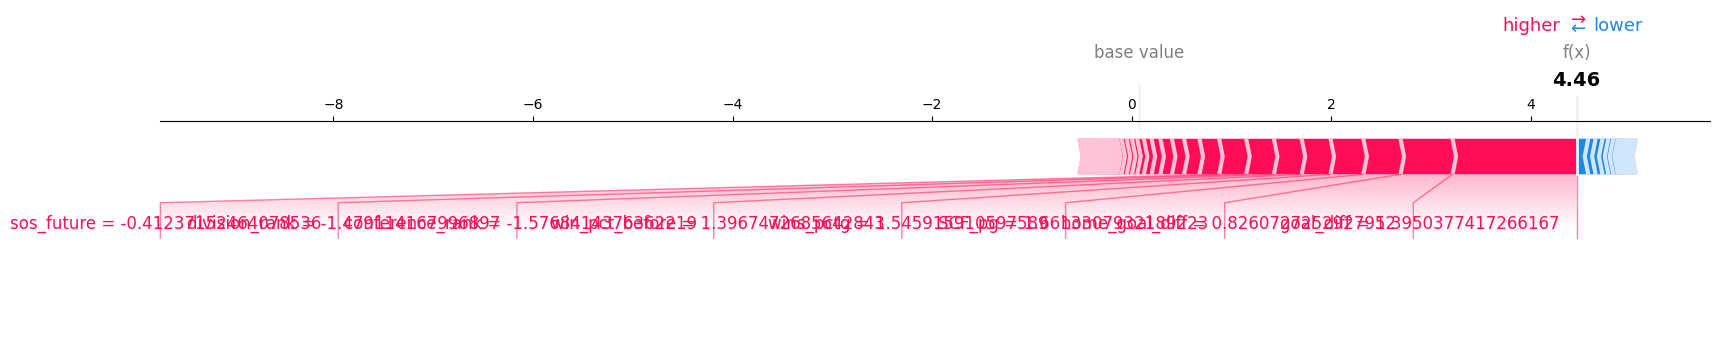

In [147]:
row_idx = current_df.index[current_df["tri_code"] == "COL"][-1]

shap.force_plot(
    explainer.expected_value,
    shap_values[row_idx],
    X_shap_scaled.loc[[row_idx]],
    matplotlib=True
)


In [148]:
shap_values = explainer.shap_values(X_shap_scaled)


In [149]:
shap_df = pd.DataFrame(
    shap_values,
    columns=FEATURE_COLS,
    index=current_df.index
)


In [150]:
latest_idx = (
    current_df
    .sort_values(["team_id", "game_date"])
    .groupby("team_id")
    .tail(1)
    .index
)

shap_latest = shap_df.loc[latest_idx]
meta_latest = current_df.loc[latest_idx]


In [151]:
def top_negative_drivers(shap_row, n=3):
    sorted_row = shap_row.sort_values()
    return list(zip(sorted_row.index[:n], sorted_row.values[:n]))


In [152]:
records = []

for idx, shap_row in shap_latest.iterrows():
    sinks = top_negative_drivers(shap_row, n=3)

    records.append({
        "team_name": meta_latest.loc[idx, "team_name"],
        "tri_code": meta_latest.loc[idx, "tri_code"],
        "season_id": meta_latest.loc[idx, "season_id"],
        "biggest_sinker": f"{sinks[0][0]} ({sinks[0][1]:.3f})",
        "second_biggest_sinker": f"{sinks[1][0]} ({sinks[1][1]:.3f})",
        "third_biggest_sinker": f"{sinks[2][0]} ({sinks[2][1]:.3f})",
        "biggest_sinker_value": sinks[0][1],
    })


In [153]:
sinker_df = pd.DataFrame(records)

sinker_df = sinker_df.sort_values(
    "biggest_sinker_value"
).reset_index(drop=True)

sinker_df


,team_name,tri_code,season_id,biggest_sinker,second_biggest_sinker,third_biggest_sinker,biggest_sinker_value
0,St. Louis Blues,STL,20252026,goal_diff (-1.548),wins_pctg (-0.416),rotw_pctg (-0.381),-1.547718
1,Nashville Predators,NSH,20252026,goal_diff (-1.350),conference_rank (-0.466),wins_pctg (-0.387),-1.350139
2,Vancouver Canucks,VAN,20252026,goal_diff (-0.535),conference_rank (-0.534),sos_future (-0.386),-0.535211
3,Calgary Flames,CGY,20252026,conference_rank (-0.500),goal_diff (-0.421),wins_pctg (-0.379),-0.499775
4,New York Rangers,NYR,20252026,sos_future (-0.486),conference_rank (-0.416),wins_pctg (-0.294),-0.485605
5,Toronto Maple Leafs,TOR,20252026,conference_rank (-0.429),goal_diff (-0.418),sos_future (-0.401),-0.429386
6,Buffalo Sabres,BUF,20252026,sos_future (-0.420),conference_rank (-0.375),rotw_pctg (-0.296),-0.419515
7,San Jose Sharks,SJS,20252026,sos_future (-0.415),shot_attempts_against_per_game (-0.334),shot_attempts_for_per_game (-0.263),-0.415354
8,Philadelphia Flyers,PHI,20252026,rotw_pctg (-0.406),sos_future (-0.309),rush_for_per_game (-0.159),-0.406440
9,Chicago Blackhawks,CHI,20252026,sos_future (-0.397),wins_pctg (-0.296),shot_attempts_against_per_game (-0.289),-0.396649


## STEP 1 — Tag features by pressure sensitivity

In [154]:
# ----------------------------------------
# Feature interpretation taxonomy
# v1.1 — pressure-refined
# ----------------------------------------

PRESSURE_SENSITIVE = {
    # -------------------------------------------------
    # Special teams & discipline (amplify race pressure)
    # -------------------------------------------------
    "pk_goals_against_pg",
    "pk_pct",
    "pk_time_on_ice_pg",
    "penalties_taken_pg",
    "c_pp_net_g",
    "times_sh_pg",

    # -------------------------------------------------
    # Transition / rush (harder to sustain under pressure)
    # -------------------------------------------------
    "rush_for_per_game",
    "rush_diff_per_game",
    "rush_against_per_game",
    "rush_shots_against",

    # -------------------------------------------------
    # Margins & close-game resolution
    # -------------------------------------------------
    "goal_diff",
    "home_goal_diff",
    "goal_diff_pctg",
    "one_goal_win_pct",
    "rotw_pctg",
    "rw",
    "regulation_wins",
    "ot_wins",
    "ot_losses",
    "so_wins",
    "so_losses",

    # -------------------------------------------------
    # Standings conversion & playoff leverage
    # (internal performance under external pressure)
    # -------------------------------------------------
    "points",
    "points_pct",
    "projected_points",
    "win_pct_before",

    # -------------------------------------------------
    # Possession balance under stress
    # -------------------------------------------------
    "c_shot_pct",
    "corsi_diff_per_game",
    "c_corsi_diff",
    "c_pdo",

    # -------------------------------------------------
    # Road resilience (schedule + mental stress test)
    # -------------------------------------------------
    "road_goal_diff",
    "road_rw",
    "road_ot_losses",
    "road_points",
    "road_wins",
    "road_rotw",

    # -------------------------------------------------
    # Short-horizon performance (signal compression zone)
    # -------------------------------------------------
    "last_10_rw",
    "last_10_goal_diff",
}

PRESSURE_AGNOSTIC = {
    # -------------------------------------------------
    # Possession & shot volume (baseline quality)
    # -------------------------------------------------
    "corsi_for_pg",
    "SCF_pg",
    "xGF_pg",
    "shots_for_pg",

    # -------------------------------------------------
    # Offensive ceiling (less race-dependent)
    # -------------------------------------------------
    "goals_for_pg",
    "pp_goals_pg",

    # -------------------------------------------------
    # Goaltending baseline (talent > context)
    # -------------------------------------------------
    "c_sv_pct",
}

EXOGENOUS_PRESSURE = {
    # -------------------------------------------------
    # Structural / environment features (not controllable)
    # -------------------------------------------------
    "division_rank",
    "conference_rank",
    "wildcard_rank",
    "conference_team_count",

    # -------------------------------------------------
    # Wild-card race geometry
    # -------------------------------------------------
    "wc_points_margin",
    "wc_points_pct_margin",
    "wc_teams_within_2pts",
    "wc_teams_within_4pts",
    "wc_teams_within_6pts",

    # -------------------------------------------------
    # Schedule / opponent difficulty
    # -------------------------------------------------
    "sos_future",
}

CONTEXT_AMPLIFIED_EXECUTION = {
    # Core performance that matters more in tight races
    "points_pct",
    "goal_diff_pctg",
    "projected_points",
    "pt_pct_x_sos",

    # Possession & shot quality under pressure
    "corsi_diff_per_game",
    "c_corsi_diff",
    "c_shot_pct",

    # Transition margins
    "rush_for_per_game",
    "rush_diff_per_game",

    # Home / road split effects
    "road_goal_diff",
    "road_points",
    "home_goal_diff",

    # Schedule-scaled metrics
    "conference_team_count",
}



In [155]:
def classify_feature(feature):
    if feature in EXOGENOUS_PRESSURE:
        return "Environment"
    elif feature in PRESSURE_SENSITIVE:
        return "Pressure-Sensitive"
    elif feature in PRESSURE_AGNOSTIC:
        return "Pressure-Agnostic"
    elif feature in CONTEXT_AMPLIFIED_EXECUTION:
        return "Context-Amplified"
    else:
        return "Unclassified"


## STEP 2 — Build a team robustness diagnostic

In [156]:
def team_robustness_breakdown(
    team_code,
    current_df,
    shap_df,
):
    """
    Quantifies how much a team's negative SHAP impact
    comes from environment vs pressure-sensitive performance.
    """

    # Locate latest snapshot
    team_rows = current_df[current_df["tri_code"] == team_code]
    if team_rows.empty:
        raise ValueError(f"{team_code} not found")

    row_idx = team_rows.sort_values("game_date").index[-1]
    shap_row = shap_df.loc[row_idx]

    # Only negative contributors
    negative = shap_row[shap_row < 0]

    records = []
    for feature, value in negative.items():
        records.append({
            "feature": feature,
            "impact": value,
            "category": classify_feature(feature)
        })

    df = pd.DataFrame(records)

    summary = (
        df.groupby("category")["impact"]
        .sum()
        .sort_values()
    )

    return df.sort_values("impact"), summary


In [157]:
detail, summary = team_robustness_breakdown(
    team_code="COL",
    current_df=current_df,
    shap_df=shap_df
)

print("📉 Negative SHAP impact by category:")
display(summary)

print("\n🔍 Biggest individual sinkers:")
display(detail.head(10))


📉 Negative SHAP impact by category:


category
Unclassified         -0.431657
Pressure-Sensitive   -0.160126
Environment          -0.000552
Name: impact, dtype: float64


🔍 Biggest individual sinkers:


,feature,impact,category
20,SCA_pg,-0.116237,Unclassified
6,ppng_rank,-0.073632,Unclassified
5,net_pp_pct,-0.068757,Unclassified
10,rush_for_per_game,-0.058793,Pressure-Sensitive
1,sos_past,-0.049014,Unclassified
11,rush_against_per_game,-0.045584,Pressure-Sensitive
28,gf_pctg,-0.033712,Unclassified
44,ot_games_pct,-0.026476,Unclassified
40,road_rw,-0.014473,Pressure-Sensitive
13,shots_diff_per_game,-0.012762,Unclassified


In [158]:
# detail, summary = team_robustness_breakdown(
#     "BOS",
#     current_df,
#     shap_df
# )

# detail.query("category == 'Unclassified'")


## Pressure Leverage Table

In [159]:
FEATURE_METADATA = {

    # =====================================================
    # PRESSURE-SENSITIVE (FIXABLE EXECUTION)
    # =====================================================
    # These represent true execution under stress:
    # discipline, special teams, rush defense, close games

    # Transition & rush defense
    "rush_against_per_game":    ("Pressure-Sensitive", "High"),

    # Close-game & resolution skills
    "ot_wins":                  ("Pressure-Sensitive", "Low"),
    "rw":                       ("Pressure-Sensitive", "Medium"),
    "home_rotw":                ("Pressure-Sensitive", "Medium"),
    "last_10_rw":               ("Pressure-Sensitive", "Medium"),

    # =====================================================
    # CONTEXT-AMPLIFIED EXECUTION (MARGINS MATTER MORE)
    # =====================================================
    # These are NOT failures under pressure —
    # they are normal performance metrics whose impact
    # increases when the race is tight

    # Core performance / margins
    "points_pct":               ("Context-Amplified", "Low"),
    "gf_pctg":                  ("Context-Amplified", "Low"),
    "goal_diff_pctg":           ("Context-Amplified", "Low"),
    "projected_points":         ("Context-Amplified", "Low"),
    "pt_pct_x_sos":             ("Context-Amplified", "Low"),

    # Possession & shot quality
    "c_shot_pct":               ("Context-Amplified", "Low"),
    "corsi_diff_per_game":      ("Context-Amplified", "Low"),
    "c_corsi_diff":             ("Context-Amplified", "Low"),
    "c_pdo":                    ("Context-Amplified", "Low"),

    # Transition margins (offensive side)
    "rush_for_per_game":        ("Context-Amplified", "Low"),
    "rush_diff_per_game":       ("Context-Amplified", "Low"),

    # Home / road splits
    "road_goal_diff":           ("Context-Amplified", "Low"),
    "road_points":              ("Context-Amplified", "Low"),
    "road_rw":                  ("Context-Amplified", "Low"),
    "road_ot_losses":           ("Context-Amplified", "Low"),
    "home_goal_diff":           ("Context-Amplified", "Low"),

    # =====================================================
    # PRESSURE-AGNOSTIC (BASELINE QUALITY)
    # =====================================================
    # These describe team ceiling, not race behavior

    "SCF_pg":                   ("Pressure-Agnostic", "Low"),
    "shots_for_pg":             ("Pressure-Agnostic", "Low"),
    "xGF_pg":                   ("Pressure-Agnostic", "Low"),
    "c_sv_pct":                 ("Pressure-Agnostic", "Low"),

    # =====================================================
    # ENVIRONMENT (NOT FIXABLE)
    # =====================================================
    # Structural constraints of the league / standings

    "division_rank":            ("Environment", "None"),
    "conference_rank":          ("Environment", "None"),
    "wildcard_rank":            ("Environment", "None"),
    "wc_points_margin":         ("Environment", "None"),
    "wc_teams_within_2pts":     ("Environment", "None"),
    "wc_teams_within_4pts":     ("Environment", "None"),
    "wc_teams_within_6pts":     ("Environment", "None"),
    "conference_team_count":    ("Environment", "None"),
    "sos_future":               ("Environment", "None"),
}


In [160]:
def build_pressure_leverage_table(
    shap_series: pd.Series,
    feature_metadata: dict,
    n=15
):
    df = (
        shap_series
        .sort_values()
        .head(n)
        .reset_index()
        .rename(columns={"index": "feature", 0: "shap_impact"})
    )

    df[["category", "fixability"]] = df["feature"].apply(
        lambda f: feature_metadata.get(f, ("Unclassified", "Unknown"))
    ).apply(pd.Series)

    return df


How to read it

High fixability + large negative SHAP = coaching / systems leverage

Medium fixability = tactical emphasis

Environment = context, not blame

This table answers:

“If COLton improves just two things, what should they be?”

In [161]:
leverage = build_pressure_leverage_table(shap_row, FEATURE_METADATA)
leverage


,feature,624,category,fixability
0,division_rank,-0.245677,Environment,None
1,rush_for_per_game,-0.155036,Context-Amplified,Low
2,ot_games_pct,-0.117278,Unclassified,Unknown
3,c_shot_pct,-0.076032,Context-Amplified,Low
4,win_pct_before,-0.075022,Unclassified,Unknown
5,ppng_rank,-0.073924,Unclassified,Unknown
6,c_pp_net_g,-0.065289,Unclassified,Unknown
7,net_pp_pct,-0.063777,Unclassified,Unknown
8,gf_pctg,-0.061551,Context-Amplified,Low
9,home_goal_diff,-0.048119,Context-Amplified,Low


## Pressure Sensitivity Score

“How fragile is this team in a tight race?”

This becomes a single number you can track over time. Pressure Sensitivity Score =
(sum of negative Pressure-Sensitive SHAP) ÷ (total negative SHAP)


In [162]:
def pressure_sensitivity_score(shap_series, feature_metadata):
    neg = shap_series[shap_series < 0]

    total_neg = neg.sum()
    if total_neg == 0:
        return 0.0

    ps_neg = neg[
        neg.index.map(
            lambda f: feature_metadata.get(f, ("", ""))[0]
        ) == "Pressure-Sensitive"
    ].sum()

    return float(ps_neg / total_neg)


Interpretation guide:
Score	Meaning
- < 0.25	Stable contender
- 0.25–0.45	Normal playoff pressure
- 0.45–0.65	Bubble-fragile
- "> 0.65"	Execution-dependent team

Boston being high here = race amplifies weaknesses

In [163]:
ps_score = pressure_sensitivity_score(shap_row, FEATURE_METADATA)
ps_score


0.00750719616189599

## Environment vs Execution Visual

“Is this luck or performance?”

This is the chart that tells the story instantly.

In [164]:
def shap_by_category(shap_series, feature_metadata):
    df = shap_series.reset_index()
    df.columns = ["feature", "impact"]

    df["category"] = df["feature"].apply(
        lambda f: feature_metadata.get(f, ("Unclassified",))[0]
    )

    return (
        df[df["impact"] < 0]
        .groupby("category")["impact"]
        .sum()
        .sort_values()
    )


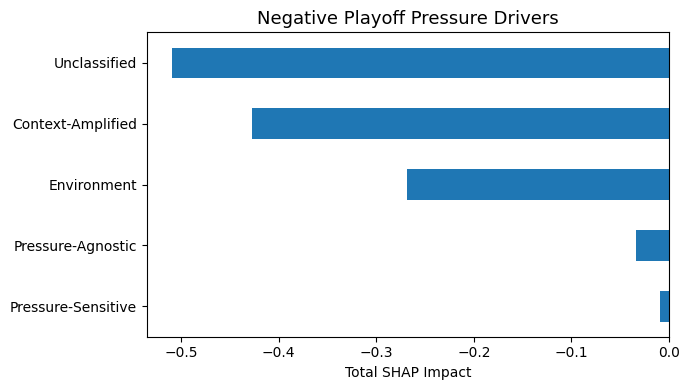

In [165]:
import matplotlib.pyplot as plt

cat_impact = shap_by_category(shap_row, FEATURE_METADATA)

plt.figure(figsize=(7, 4))
cat_impact.plot(kind="barh")

plt.title("Negative Playoff Pressure Drivers", fontsize=13)
plt.xlabel("Total SHAP Impact")
plt.ylabel("")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


How to read it

Pressure-Sensitive dominating → fixable execution issues

Environment dominating → schedule / race reality

Pressure-Agnostic dominating → roster ceiling issues

“This team is hurting itself more than the league is hurting it.”

≥ 0.85  → High-confidence territory
0.65–0.85 → Solid contender
0.45–0.65 → True bubble
0.25–0.45 → Outside but alive
< 0.25 → Long shot


In [166]:
def playoff_tier(prob, pressure_sensitivity):
    if prob >= 0.85 and pressure_sensitivity <= 0.40:
        return "Lock"
    elif prob >= 0.65 and pressure_sensitivity <= 0.45:
        return "Likely"
    elif prob >= 0.45:
        return "Bubble"
    elif prob >= 0.25 and pressure_sensitivity > 0.30:
        return "Likely Out"
    else:
        return "Out"


In [167]:
latest_snapshot = (
    current_df
    .sort_values(["team_id", "game_date"])
    .groupby("team_id", as_index=False)
    .tail(1)
)

latest_snapshot.head()

,season_id,game_id,game_date,team_id,tri_code,team_name,win,wins_before,games_before,win_pct_before,sos_past,sos_future,pp_opp,pp_opp_pg,pp_toi,pp_gpg,pp_net_g,pp_net_gpg,pp_pct,pp_net_pct,sh_ga_pg,times_sh_pg,pk_net_pct,pk_pct,pk_net_g,pk_net_gpg,pk_toi_pg,pp_ga_pg,sh_gf_pg,c_pp_opps,c_pp_net_g,net_pp_pct,ppng_rank,c_pp_ga,c_times_sh,net_pk_pct,pk_rank,rush_shots_for,rush_shots_against,rush_shot_differential,c_rush_shots_for,c_rush_shots_against,c_rush_diff,rush_for_per_game,rush_against_per_game,rush_diff_per_game,shot_attempts_for,shot_attempts_against,shot_attempts_differential,corsi_for,corsi_against,corsi_diff,c_shots_diff,games_played,shot_attempts_for_per_game,shot_attempts_against_per_game,shots_diff_per_game,SCF,SCSF,SCGF,SCA,HDCF,MDCF,LDCF,HDCA,MDCA,LDCA,HDCF_pct,HDCA_pct,MDCF_pct,MDCA_pct,LDCF_pct,LDCA_pct,c_SCF,c_SCSF,c_SCGF,c_SCA,SCF_pg,SCA_pg,c_HDCF,c_HDCA,c_MDCF,c_MDCA,c_LDCF,c_LDCA,shot_pct,sv_pct,pdo,c_goals_for,c_hd_sog,c_md_sog,c_ld_sog,c_hd_goals,c_md_goals,c_ld_goals,c_goals_against,c_hd_against,c_md_against,c_ld_against,c_shot_pct,c_sv_pct,c_pdo,c_shots_for,c_shots_against,c_corsi_for,c_corsi_against,c_corsi_diff,corsi_diff_per_game,games_remaining,wins,wins_pctg,losses,ot_losses,rotw,rotw_pctg,rw,so_losses,so_wins,points,points_pct,projected_points,in_playoff_spot,gf_pctg,goal_diff,goal_diff_pctg,streak_count,last_10_gp,last_10_wins,last_10_losses,last_10_otl,last_10_points,last_10_gf,last_10_ga,last_10_goal_diff,last_10_rotw,last_10_rw,home_gp,home_wins,home_losses,home_otlosses,home_rotw,home_rw,home_points,home_gf,home_ga,home_goal_diff,road_gp,road_wins,road_losses,road_ot_losses,road_rotw,road_rw,road_points,road_gf,road_ga,road_goal_diff,division,division_rank,conference,conference_rank,wildcard_rank,ot_wins,overtimes,ot_games_pct,pt_pct_x_sos,gaa_x_sv,gd_x_rushdiff,pk_load_x_pk_pct,conference_team_count,conf_playoff_chance_baseline,streak_signed,rank_bucket,wc2_points,wc2_points_pct,wc_points_margin,wc_points_pct_margin,in_wc_spot,in_div_top3,on_wc_bubble,wc_teams_within_2pts,wc_teams_within_4pts,wc_teams_within_6pts,playoff_prob_row,season_bucket,playoff_prob_display
358,20252026,2025020354,2025-11-24,1,NJD,New Jersey Devils,1,13,21,0.619048,0.467464,0.488773,1,1.0,120.0,0.0,0,0.0,0.00,0.00,0.0,3.0,0.666666,0.66666,-1,-1.0,310.0,1.0,0.0,56.0,13.0,23.2,5,11.0,64.0,17.2,11,5,6,-1,140,142,-2,6.363636,6.454545,-0.090909,50,50,0,27,32,-5,10,22,61.318182,60.863636,0.454545,33,20,4,81,15,13,22,17,17,19,0.468750,0.531250,0.433333,0.566667,0.536585,0.463415,733,656,71,1470,33.318182,66.818182,337,357,395,406,649,644,20.000000,91.428571,111.428571,71,156,164,348,31,27,19,68,146,188,304,0.108232,0.891200,99.943171,1349,1339,939,915,24,1.090909,60,14,0.636364,7,1,12,0.545455,9,0,2,29,0.659091,108,0,3.136364,2,0.090909,1.0,10,5,4,1,11,24,31,-7,3,1,9,8,0,1,7,5,17,31,19,12,13,6,7,0,5,4,12,38,48,-10,Metropolitan,2,Eastern,2,0,3,4,0.18,0.322146,2.756618,-2,1.99998,16,0.5,1,tier1_elite,25.0,0.568182,4.0,0.090909,1,1,0,0,0,0,0.923342,mid,0.923342
403,20252026,2025020349,2025-11-23,2,NYI,New York Islanders,1,12,22,0.545455,0.511835,0.568419,2,2.0,139.0,0.0,0,0.0,0.00,0.00,0.0,1.0,1.000000,1.00000,0,0.0,120.0,0.0,0.0,75.0,8.0,10.7,29,12.0,71.0,16.9,9,10,5,5,143,144,-1,6.217391,6.260870,-0.043478,85,84,1,60,57,3,17,23,59.043478,58.304348,0.739130,41,37,2,77,19,33,35,18,26,34,0.513514,0.486486,0.559322,0.440678,0.507246,0.492754,764,668,73,1564,33.217391,68.000000,339,357,442,447,616,625,5.405405,95.238095,100.643501,73,158,184,336,30,27,17,68,204,182,282,0.109281,0.896024,100.530590,1358,1341,983,957,26,1.130435,59,13,0.565217,8,2,12,0.521739,9,2,1,28,0.608696,100,0,3.086957,5,0.217391,1.0,10,7,3,0,14,28,20,8,6,3,10,5,4,1,4,4,11,29,29,0,13,8,4,1,8,5,17,42,37,5,Metropolitan,2,Eastern,2,0,3,5,0.22,0.345995,0.000000,25,1.00000,16,0.5,1,tier1_elite,22.0,0.500000,6.0,0.108696,1,1,0,0,0,0,0.698378,mid,0.698378
427,20252026,2025020355,2025-11-24,3,NYR,New York Rangers,1,10,23,0.434783,0.488283,0.559822,0,0.0,0.0,0.0,0,0.0,N

In [168]:
latest_snapshot["playoff_tier"] = latest_snapshot.apply(
    lambda r: playoff_tier(
        r["playoff_prob_display"],
        r["pressure_sensitivity_score"]
    ),
    axis=1
)


KeyError: 'pressure_sensitivity_score'